# Unidad 3 — Introducción a Deep Learning

**Módulo 6: Modelos Avanzados de IA y Aplicaciones Económicas — CEC EPN / Banco Central del Ecuador**  
**Fechas:** 18-11 (3 h), 19-11 (3 h) y 23-11-2026 (1 h) · Contenidos 3.1 a 3.5

La Unidad 2 terminó con una frase: la regresión logística toma las variables del cliente, las multiplica por unos pesos, las suma y pasa el resultado por una curva en forma de S. **Eso es una neurona artificial.** Una red neuronal son muchas de esas neuronas conectadas en capas.

**Principio de la unidad:** antes de entrenar una red con Keras, tienes que poder **calcular a mano la salida de una neurona** y explicar cómo aprende. Las partes 1 a 3 no usan Keras: solo aritmética y `numpy`. Keras aparece en la parte 4.

## Objetivos

Al terminar deberías poder explicar, con tus propias palabras:

- qué son las **entradas, los pesos, el sesgo y la activación** de una neurona, y calcular su salida;
- cómo pasa un dato por una red de varias capas (**propagación hacia adelante**);
- qué mide la **función de pérdida** y cómo el **descenso del gradiente** ajusta los pesos;
- qué reparte la **retropropagación**;
- qué son las **épocas**, los **lotes** y la **tasa de aprendizaje**, y por qué hay que **normalizar**;
- cómo reconocer el **sobreajuste** en una curva de aprendizaje y cómo frenarlo;
- si una red neuronal le gana, o no, a los modelos de las Unidades 1 y 2 en nuestro caso.

## Ruta de la unidad

| Parte | Contenido | Jornada | Qué haremos | Herramienta |
|---|---|---|---|---|
| 1 | 3.1 | 18-11 | De la regresión logística a la neurona; calcular una neurona a mano | aritmética, `numpy` |
| 2 | 3.2 | 18-11 | Capas y propagación hacia adelante a mano | `numpy` |
| 3 | 3.3 | 18-11 | Pérdida, descenso del gradiente y retropropagación | `numpy` |
| 4 | 3.4 | 19-11 | Épocas, lotes, tasa de aprendizaje, normalización y sobreajuste | **Keras** |
| 5 | 3.5 | 19-11 y 23-11 | La red final frente a las líneas base; Actividad 3 | Keras, scikit-learn |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib scikit-learn tensorflow

In [2]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'impago_tarjetas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /home/claude/m6/datos


# 0. Librerías

| Herramienta | Para qué |
|---|---|
| `numpy` | las cuentas de las partes 1 a 3: una neurona es una suma de productos |
| `keras` (viene dentro de TensorFlow) | construir y entrenar redes neuronales en pocas líneas |
| `StandardScaler` | normalizar las entradas |
| `LogisticRegression`, `RandomForestClassifier`, `GradientBoostingClassifier` | las líneas base de las Unidades 1 y 2 |

**Keras y TensorFlow:** TensorFlow es el motor que hace las cuentas (y calcula los gradientes); Keras es la forma sencilla de usarlo. En Colab ya vienen instalados. En tu computador, la celda de instalación de arriba los descarga la primera vez (pesan varios cientos de MB).

**Sobre los números de este notebook:** una red neuronal empieza con pesos al azar. Fijamos la semilla para que los resultados se repitan, pero entre computadores distintos pueden cambiar en el tercer decimal. Las conclusiones no cambian.

In [3]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'      # oculta los mensajes internos de TensorFlow

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')
print('Keras', keras.__version__)

Keras 3.15.1


El caso del módulo, con la misma partición de las Unidades 1 y 2.

In [4]:
datos = pd.read_csv(DATA_DIR / 'impago_tarjetas.csv')

# X: lo que sabemos del cliente en septiembre · y: si no pagó en octubre (1 = impago)
X = datos.drop(columns=['id', 'impago'])
y = datos['impago']

# La misma partición en todo el módulo (misma semilla): 60 % Train, 20 % Validation, 20 % Test.
# stratify=y mantiene el 22 % de impagos en las tres partes.
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print('Train:', X_train.shape, '· Validation:', X_val.shape, '· Test:', X_test.shape)
print('Tasa de impago -> Train:', round(y_train.mean(), 3), '· Validation:', round(y_val.mean(), 3), '· Test:', round(y_test.mean(), 3))

Train: (18000, 23) · Validation: (6000, 23) · Test: (6000, 23)
Tasa de impago -> Train: 0.221 · Validation: 0.221 · Test: 0.221


# 1. De la regresión logística a la neurona (3.1)

## 1.1 Las piezas de una neurona

Una neurona hace **dos operaciones**:

**Paso 1. Sumar las entradas, cada una con su peso.**

$$z = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n + b$$

**Paso 2. Pasar esa suma por una función de activación.**

$$a = f(z)$$

| Símbolo | Nombre | Qué es | En el caso |
|---|---|---|---|
| $x_1, x_2, \ldots$ | **entradas** | los datos del cliente | meses de atraso, cupo |
| $w_1, w_2, \ldots$ | **pesos** | cuánto importa cada entrada y en qué dirección. Positivo: sube el riesgo. Negativo: lo baja | se **aprenden** |
| $b$ | **sesgo** | el punto de partida cuando todas las entradas valen cero | se **aprende** |
| $z$ | **suma ponderada** | el "puntaje" antes de la activación | cualquier número |
| $f$ | **activación** | la función que transforma el puntaje | sigmoide |
| $a$ | **salida** | lo que la neurona responde | probabilidad de impago |

Piensa en un analista de crédito que revisa una solicitud: mira cada dato, **le da más o menos importancia** (pesos), parte de una opinión inicial (sesgo), suma todo y da un veredicto (activación).

## 1.2 La activación sigmoide

Para que la salida sea una probabilidad, entre 0 y 1, se usa la **sigmoide**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Tres valores para tener a mano:

| z | σ(z) | Lectura |
|---:|---:|---|
| −2 | 0.12 | puntaje muy negativo: probabilidad baja |
| 0 | 0.50 | puntaje cero: mitad y mitad |
| 2 | 0.88 | puntaje muy positivo: probabilidad alta |

## 1.3 Una neurona real: la regresión logística con dos variables

Para tener pesos reales, entrenamos una regresión logística con solo dos entradas:

- $x_1$ = meses de atraso en septiembre;
- $x_2$ = límite de crédito, **en cientos de miles** (un cupo de 50 000 es 0.5).

In [5]:
def dos_entradas(tabla):
    """Las dos entradas de nuestra neurona: atraso (meses) y límite de crédito (cientos de miles)."""
    return np.column_stack([tabla['atraso_sep'], tabla['limite_credito'] / 100_000])

X2_train, X2_val = dos_entradas(X_train), dos_entradas(X_val)

logistica_2 = LogisticRegression(C=1e6, max_iter=1000).fit(X2_train, y_train)   # C grande = sin regularización

print('Peso del atraso  (w1):', round(logistica_2.coef_[0, 0], 2))
print('Peso del límite  (w2):', round(logistica_2.coef_[0, 1], 2))
print('Sesgo            (b) :', round(logistica_2.intercept_[0], 2))
print('AUC en Validation    :', round(roc_auc_score(y_val, logistica_2.predict_proba(X2_val)[:, 1]), 3))

Peso del atraso  (w1): 0.72
Peso del límite  (w2): -0.2
Sesgo            (b) : -1.1
AUC en Validation    : 0.71


**Qué obtuvimos:** $w_1 = 0.72$, $w_2 = -0.20$ y $b = -1.10$.

- **Peso del atraso, positivo (0.72):** cada mes de atraso **sube** el puntaje.
- **Peso del límite, negativo (−0.20):** un cupo mayor **baja** el puntaje (el banco da cupos altos a clientes con mejor historial).
- **Sesgo, negativo (−1.10):** un cliente con atraso 0 y cupo 0 parte de un puntaje bajo, porque la mayoría de los clientes paga.

## 1.4 A mano: calcular la neurona para dos clientes

**Cliente 1: 2 meses de atraso y cupo de 50 000** ($x_1 = 2$, $x_2 = 0.5$).

Paso 1, la suma ponderada:

$$z = (0.72 \times 2) + (-0.20 \times 0.5) + (-1.10) = 1.44 - 0.10 - 1.10 = 0.24$$

Paso 2, la activación:

$$a = \sigma(0.24) = \frac{1}{1 + e^{-0.24}} = \frac{1}{1 + 0.787} = 0.56$$

**Probabilidad de impago: 56 %.**

**Cliente 2: al día y cupo de 200 000** ($x_1 = 0$, $x_2 = 2$).

$$z = (0.72 \times 0) + (-0.20 \times 2) + (-1.10) = 0 - 0.40 - 1.10 = -1.50$$

$$a = \sigma(-1.50) = \frac{1}{1 + e^{1.50}} = \frac{1}{1 + 4.48} = 0.18$$

**Probabilidad de impago: 18 %.**

Comprobamos con `numpy`.

In [6]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def neurona(x, w, b):
    """Salida de una neurona: suma ponderada y activación sigmoide."""
    z = np.dot(x, w) + b        # w1*x1 + w2*x2 + b
    return sigmoide(z)

w = np.array([0.72, -0.20])
b = -1.10

for nombre, x in [('Cliente 1 (atraso 2, cupo 50 000)', [2, 0.5]), ('Cliente 2 (al día, cupo 200 000)', [0, 2.0])]:
    z = np.dot(x, w) + b
    print(f'{nombre}: z = {z:.2f} -> salida = {neurona(x, w, b):.3f} · scikit-learn dice {logistica_2.predict_proba([x])[0, 1]:.3f}')

Cliente 1 (atraso 2, cupo 50 000): z = 0.24 -> salida = 0.560 · scikit-learn dice 0.559
Cliente 2 (al día, cupo 200 000): z = -1.50 -> salida = 0.182 · scikit-learn dice 0.181


**Lectura:** el cálculo a mano, la función `neurona` y scikit-learn coinciden. **Una regresión logística es una red neuronal de una sola neurona con activación sigmoide.**

## 1.5 Otras activaciones

La sigmoide se usa en la **salida** cuando queremos una probabilidad. En las neuronas intermedias se usan otras:

| Activación | Fórmula | Rango | Dónde se usa |
|---|---|---|---|
| **Sigmoide** | $1 / (1 + e^{-z})$ | 0 a 1 | salida de clasificación de sí o no |
| **Tanh** | — | −1 a 1 | capas ocultas (redes antiguas, series) |
| **ReLU** | $\max(0, z)$ | 0 a infinito | **capas ocultas, la opción por defecto** |
| **Lineal** | $z$ | cualquier número | salida de regresión (pronosticar un valor) |

**ReLU** es la más simple: si el puntaje es negativo, responde 0 (la neurona "se apaga"); si es positivo, lo deja pasar.

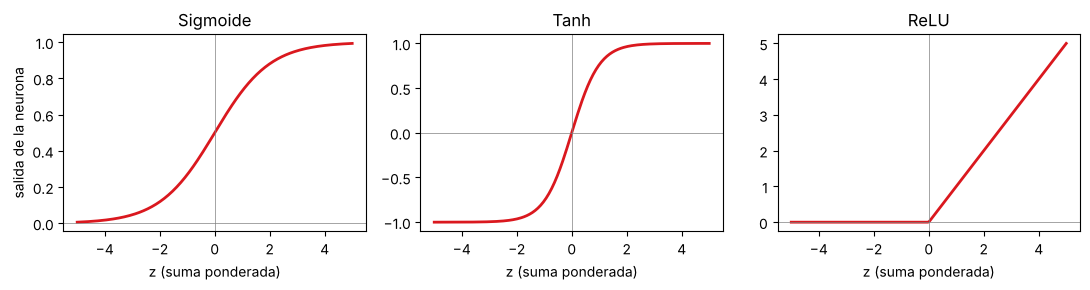

In [7]:
z = np.linspace(-5, 5, 200)
fig, ejes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (nombre, valores) in zip(ejes, [('Sigmoide', sigmoide(z)), ('Tanh', np.tanh(z)), ('ReLU', np.maximum(0, z))]):
    ax.plot(z, valores, color='#DA181E', linewidth=2)
    ax.axhline(0, color='gray', linewidth=0.5); ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_title(nombre); ax.set_xlabel('z (suma ponderada)')
ejes[0].set_ylabel('salida de la neurona')
plt.tight_layout(); plt.show()

**¿Por qué hace falta una activación?** Sin ella, una neurona solo suma y multiplica. Y una suma de sumas sigue siendo una suma: por muchas capas que pongamos, la red entera equivaldría a **una sola regresión lineal**. La activación es lo que permite que la red aprenda curvas, umbrales y combinaciones.

# 2. Perceptrón, capas y propagación hacia adelante (3.2)

## 2.1 El perceptrón y su límite

El **perceptrón** (1958) es la neurona más antigua: su activación es un escalón (responde 1 si z > 0 y 0 si no). Una sola neurona, con escalón o con sigmoide, solo puede separar a los clientes con **una línea recta**: "si 0.72 × atraso − 0.20 × cupo es mayor que 1.10, impaga".

Eso no alcanza cuando la respuesta depende de **combinaciones**. Miremos la tasa de impago real por atraso y por tamaño del cupo.

In [8]:
tabla_combinada = pd.crosstab(
    pd.cut(X_train['atraso_sep'], [-3, 0, 1, 8], labels=['al día', '1 mes', '2+ meses']).rename('Atraso'),
    pd.cut(X_train['limite_credito'], [0, 50_000, 200_000, 1_000_000], labels=['cupo bajo', 'cupo medio', 'cupo alto']).rename('Cupo'),
    values=y_train, aggfunc='mean').round(2)
tabla_combinada

Cupo,cupo bajo,cupo medio,cupo alto
Atraso,,,
al día,0.20,0.13,0.10
1 mes,0.43,0.33,0.27
2+ meses,0.70,0.71,0.67


**Lectura:** entre los clientes **al día**, tener cupo bajo o alto cambia mucho la tasa de impago (de 0.20 a 0.10: la mitad). Entre los clientes con **2 o más meses de atraso**, el cupo casi no importa: impagan alrededor del 70 % en los tres grupos.

El efecto del cupo **depende** del atraso. Una sola neurona tiene un único peso para el cupo y no puede representar eso. Los árboles lo resuelven con preguntas encadenadas; las redes, con **capas**.

## 2.2 Capas

```
   ENTRADAS            CAPA OCULTA            SALIDA

   atraso  ──┬──────►  neurona h1  ──┐
             │    ╲╱                 ├──────►  neurona de salida  ──►  probabilidad
   cupo    ──┴──────►  neurona h2  ──┘                                 de impago
```

- **Capa de entrada:** los datos del cliente. No calcula nada.
- **Capa oculta:** neuronas que reciben las entradas. Cada una aprende a detectar un patrón distinto (por ejemplo, "atraso alto con cupo bajo").
- **Capa de salida:** una neurona que recibe **las salidas de la capa oculta** y da la respuesta.

Se llama "oculta" porque no vemos sus valores ni en los datos ni en la respuesta. Una red con una o más capas ocultas se llama **perceptrón multicapa (MLP)**. Con muchas capas, **deep learning**.

## 2.3 A mano: propagación hacia adelante en una red 2-2-1

Una red con 2 entradas, 2 neuronas ocultas (ReLU) y 1 de salida (sigmoide). Los pesos están inventados para que las cuentas sean fáciles; en la parte 3 veremos cómo se aprenden.

| Neurona | Peso del atraso | Peso del cupo | Sesgo |
|---|---:|---:|---:|
| h1 | 1.0 | −1.0 | −1.0 |
| h2 | −0.5 | 1.0 | 0.2 |

| Neurona | Peso de h1 | Peso de h2 | Sesgo |
|---|---:|---:|---:|
| salida | 2.0 | −1.5 | −0.6 |

**Cliente 1: atraso 2, cupo 0.5.**

**Capa oculta:**

- h1: $z = (1.0 \times 2) + (-1.0 \times 0.5) - 1.0 = 0.5$ → ReLU(0.5) = **0.5**
- h2: $z = (-0.5 \times 2) + (1.0 \times 0.5) + 0.2 = -0.3$ → ReLU(−0.3) = **0** (se apaga)

**Capa de salida** (sus entradas son 0.5 y 0):

- $z = (2.0 \times 0.5) + (-1.5 \times 0) - 0.6 = 0.4$ → σ(0.4) = **0.60**

**La red responde: 60 % de probabilidad de impago.** Propagar hacia adelante es solo eso: calcular neurona por neurona, de izquierda a derecha.

In [9]:
# Los pesos de la red 2-2-1 como matrices: una FILA por neurona, una COLUMNA por entrada
W_oculta = np.array([[1.0, -1.0],      # h1: peso del atraso, peso del cupo
                     [-0.5, 1.0]])     # h2
b_oculta = np.array([-1.0, 0.2])
w_salida = np.array([2.0, -1.5])       # peso de h1 y peso de h2
b_salida = -0.6

def relu(z):
    return np.maximum(0, z)

def red_2_2_1(x, detalle=False):
    """Propagación hacia adelante: capa oculta (ReLU) y capa de salida (sigmoide)."""
    z_oculta = W_oculta @ x + b_oculta      # '@' multiplica matriz por vector: las dos neuronas a la vez
    h = relu(z_oculta)
    z_salida = w_salida @ h + b_salida
    if detalle:
        print('  capa oculta: z =', z_oculta.round(2), '-> salidas h =', h.round(2))
        print('  capa de salida: z =', round(z_salida, 2), '-> probabilidad =', round(sigmoide(z_salida), 3))
    return sigmoide(z_salida)

print('Cliente 1 (atraso 2, cupo 0.5):'); red_2_2_1(np.array([2, 0.5]), detalle=True)
print('Cliente 2 (al día, cupo 2.0):');   red_2_2_1(np.array([0, 2.0]), detalle=True);

Cliente 1 (atraso 2, cupo 0.5):
  capa oculta: z = [ 0.5 -0.3] -> salidas h = [0.5 0. ]
  capa de salida: z = 0.4 -> probabilidad = 0.599
Cliente 2 (al día, cupo 2.0):
  capa oculta: z = [-3.   2.2] -> salidas h = [0.  2.2]
  capa de salida: z = -3.9 -> probabilidad = 0.02


**Lectura:** el Cliente 1 da 0.60, como a mano. Para el Cliente 2, h1 se apaga y h2 se enciende (2.2); como h2 tiene peso negativo en la salida, la probabilidad baja a 0.02.

Fíjate en que cada neurona oculta "se especializó": **h1 se enciende con atraso alto y cupo bajo; h2, con cupo alto y sin atraso**. La salida combina esas dos señales.

En código, una capa entera es una multiplicación de matriz por vector (`W @ x + b`). Por eso las redes se entrenan rápido: las tarjetas gráficas hacen millones de esas multiplicaciones por segundo.

## 2.4 ¿Cuántos números hay que aprender?

Cada neurona tiene un peso por entrada, más su sesgo.

| Capa | Neuronas | Entradas de cada una | Parámetros |
|---|---:|---:|---:|
| Oculta | 2 | 2 | 2 × (2 + 1) = 6 |
| Salida | 1 | 2 | 1 × (2 + 1) = 3 |
| **Total** | | | **9** |

Con las 23 variables del caso y una capa oculta de 16 neuronas: 16 × (23 + 1) + 1 × (16 + 1) = **401 parámetros**. Comprobaremos ese número con Keras.

# 3. Pérdida, descenso del gradiente y retropropagación (3.3)

Hasta aquí los pesos venían dados. Aprender es **encontrar los pesos**. Hacen falta tres piezas:

1. una forma de medir **qué tan mal** responde la red: la **función de pérdida**;
2. una forma de saber **hacia dónde mover** cada peso para mejorar: el **gradiente**;
3. una forma de repartir ese cálculo por todas las capas: la **retropropagación**.

## 3.1 La función de pérdida: cuánto me equivoqué

Para clasificación de sí o no se usa la **entropía cruzada binaria** (log-loss). Para un cliente:

- si **impagó** (y = 1): pérdida = $-\ln(p)$
- si **pagó** (y = 0): pérdida = $-\ln(1 - p)$

donde $p$ es la probabilidad de impago que dio la red y $\ln$ es el logaritmo natural. La idea: **castigar poco cuando la red acertó con seguridad y muchísimo cuando se equivocó con seguridad**.

**A mano, con tres clientes:**

| Cliente | Probabilidad que dio la red | Lo que pasó | Pérdida | Comentario |
|---|---:|---|---:|---|
| A | 0.56 | impagó | −ln(0.56) = **0.58** | acertó, sin mucha seguridad |
| B | 0.18 | pagó | −ln(1 − 0.18) = −ln(0.82) = **0.20** | acertó con seguridad: pérdida baja |
| C | 0.18 | impagó | −ln(0.18) = **1.71** | se equivocó con seguridad: pérdida alta |

**Pérdida de la red** = promedio = (0.58 + 0.20 + 1.71) / 3 = **0.83**.

Una referencia: una red que respondiera siempre "0.5" tendría pérdida −ln(0.5) = 0.69. Entrenar es **bajar ese número**.

In [10]:
def perdida(y_real, p):
    """Entropía cruzada binaria: promedio de -ln(p) si impagó y -ln(1-p) si pagó."""
    p = np.clip(p, 1e-12, 1 - 1e-12)                     # evita ln(0)
    return -np.mean(y_real * np.log(p) + (1 - y_real) * np.log(1 - p))

y_tres = np.array([1, 0, 1])
p_tres = np.array([0.56, 0.18, 0.18])
print('Pérdida de cada cliente:', (-(y_tres * np.log(p_tres) + (1 - y_tres) * np.log(1 - p_tres))).round(2))
print('Pérdida promedio       :', round(perdida(y_tres, p_tres), 2))

Pérdida de cada cliente: [0.58 0.2  1.71]
Pérdida promedio       : 0.83


## 3.2 Descenso del gradiente: bajar la montaña con niebla

Imagina que estás en una montaña con niebla y quieres llegar al valle. No ves el camino, pero **sientes la pendiente bajo los pies**. La estrategia: dar un paso en la dirección en que el suelo baja; volver a sentir la pendiente; dar otro paso.

- La **altura** es la pérdida.
- Tu **posición** son los pesos.
- La **pendiente** es el **gradiente**: dice, para cada peso, cuánto cambia la pérdida si lo muevo un poquito.
- El **tamaño del paso** es la **tasa de aprendizaje**.

La regla de actualización, para cada peso:

$$w_{\text{nuevo}} = w_{\text{actual}} - \eta \times \text{gradiente}$$

Cada símbolo: $\eta$ (eta) es la tasa de aprendizaje; el signo menos indica que vamos **cuesta abajo**.

### Sentir la pendiente con un empujón

¿Qué es el gradiente, en la práctica? Tomamos la neurona de dos entradas con todos los pesos en cero, **empujamos un peso un poquito** y miramos cuánto cambió la pérdida.

In [11]:
def perdida_neurona(w, b):
    """Pérdida en Train de la neurona de dos entradas con pesos w y sesgo b."""
    return perdida(y_train.values, sigmoide(X2_train @ w + b))

w_cero, b_cero = np.array([0.0, 0.0]), 0.0
empujon = 0.001

base = perdida_neurona(w_cero, b_cero)
print(f'Pérdida con todos los pesos en cero: {base:.4f}   (es -ln(0.5) = 0.6931: la red responde 0.5 a todos)')

# Empujamos SOLO el peso del atraso y medimos la pendiente
pendiente_w1 = (perdida_neurona(np.array([empujon, 0.0]), 0.0) - base) / empujon
pendiente_w2 = (perdida_neurona(np.array([0.0, empujon]), 0.0) - base) / empujon
pendiente_b = (perdida_neurona(w_cero, empujon) - base) / empujon
print(f'Pendiente al empujar w1 (atraso): {pendiente_w1:+.3f}')
print(f'Pendiente al empujar w2 (cupo)  : {pendiente_w2:+.3f}')
print(f'Pendiente al empujar b (sesgo)  : {pendiente_b:+.3f}')

Pérdida con todos los pesos en cero: 0.6931   (es -ln(0.5) = 0.6931: la red responde 0.5 a todos)
Pendiente al empujar w1 (atraso): -0.158
Pendiente al empujar w2 (cupo)  : +0.556
Pendiente al empujar b (sesgo)  : +0.279


**Lectura:**

- Pendiente de **w1 negativa**: si subo el peso del atraso, la pérdida **baja**. Hay que **subir** w1.
- Pendiente de **w2 positiva**: si subo el peso del cupo, la pérdida sube. Hay que **bajarlo**.
- Pendiente del **sesgo positiva**: hay que bajarlo (la red responde 0.5 a todos y solo impaga el 22 %).

Las tres direcciones coinciden con los signos que encontró la regresión logística (0.72, −0.20, −1.10). El gradiente es eso: **una flecha que dice hacia dónde mover cada peso**.

Empujar peso por peso sirve para entender, pero es lento. Para una neurona con sigmoide y esta pérdida, el gradiente tiene una fórmula exacta y muy simple:

$$\text{gradiente de } w_j = \text{promedio de } (p - y) \times x_j$$

En palabras: **el error (p − y) multiplicado por la entrada**. Si la red dijo 0.9 y el cliente pagó, el error es grande y positivo: los pesos de las entradas que estaban activas bajan.

### Entrenar la neurona con numpy

Empezamos con todos los pesos en cero y repetimos 3 000 veces: calcular salidas, calcular gradiente, dar un paso.

In [12]:
def entrenar_neurona(tasa, pasos=3000):
    """Descenso del gradiente para la neurona de dos entradas. Devuelve pesos, sesgo e historial de pérdida."""
    w, b = np.zeros(2), 0.0
    historial = []
    for paso in range(pasos):
        p = sigmoide(X2_train @ w + b)             # 1) propagación hacia adelante (los 18 000 clientes a la vez)
        error = p - y_train.values                 # 2) cuánto se equivocó con cada cliente
        gradiente_w = X2_train.T @ error / len(error)   # 3) gradiente: promedio de error x entrada
        gradiente_b = error.mean()
        w = w - tasa * gradiente_w                 # 4) un paso cuesta abajo
        b = b - tasa * gradiente_b
        historial.append(perdida(y_train.values, p))
    return w, b, historial

w_aprendido, b_aprendido, historial = entrenar_neurona(tasa=0.5)

print('Pesos aprendidos con numpy :', w_aprendido.round(2), '· sesgo:', round(b_aprendido, 2))
print('Pesos de scikit-learn      :', logistica_2.coef_[0].round(2), '· sesgo:', logistica_2.intercept_[0].round(2))
print('Pérdida: paso 1 =', round(historial[0], 4), '· paso 100 =', round(historial[99], 4), '· paso 3000 =', round(historial[-1], 4))

Pesos aprendidos con numpy : [ 0.72 -0.2 ] · sesgo: -1.1
Pesos de scikit-learn      : [ 0.72 -0.2 ] · sesgo: -1.1
Pérdida: paso 1 = 0.6931 · paso 100 = 0.4681 · paso 3000 = 0.4678


**Lectura:** partiendo de cero y repitiendo "error por entrada, un paso cuesta abajo", llegamos a **los mismos pesos que scikit-learn** (0.72, −0.20, −1.10). La pérdida bajó de 0.69 a 0.47. No hay magia: entrenar una red es repetir esta cuenta muchas veces.

## 3.3 La tasa de aprendizaje: el tamaño del paso

Probamos tres tamaños de paso.

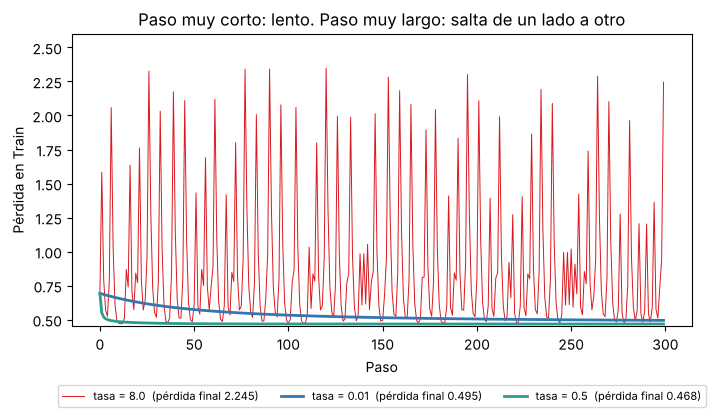

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for tasa, color, grosor in [(8.0, '#DA181E', 0.7), (0.01, '#3476B1', 2), (0.5, '#2A9D8F', 2)]:
    _, _, historial = entrenar_neurona(tasa, pasos=300)
    ax.plot(historial, color=color, linewidth=grosor, label=f'tasa = {tasa}  (pérdida final {historial[-1]:.3f})')
ax.set_xlabel('Paso'); ax.set_ylabel('Pérdida en Train'); ax.set_ylim(0.45, 2.6)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
ax.set_title('Paso muy corto: lento. Paso muy largo: salta de un lado a otro')
plt.show()

**Lectura:**

- **Tasa 0.01 (paso muy corto):** baja, pero después de 300 pasos va por 0.495 y todavía no llega al valle (0.468). Llegaría, con mucha más paciencia.
- **Tasa 0.5:** baja rápido y se estabiliza en 0.468.
- **Tasa 8.0 (paso muy largo):** salta de una ladera a la otra del valle; la pérdida sube y baja sin asentarse y termina **peor que al empezar**.

La tasa de aprendizaje es el hiperparámetro más importante de una red. Es la misma idea de la tasa de aprendizaje del boosting (Unidad 1): **pasos cortos para no pasarse**.

## 3.4 Retropropagación: repartir la culpa hacia atrás

Con una neurona, el gradiente es "error × entrada". Con capas ocultas hay un problema: **no sabemos cuál debió ser la salida de una neurona oculta**, así que no tenemos su "error".

La **retropropagación** (*backpropagation*) lo resuelve repartiendo el error de la salida hacia atrás:

1. Se calcula el error en la salida (p − y).
2. Ese error se reparte entre las neuronas ocultas **en proporción al peso con que cada una contribuyó**: la que más influyó en la respuesta se lleva más culpa.
3. Una neurona que estaba apagada (ReLU = 0) no contribuyó: no recibe culpa y sus pesos no cambian.
4. Con la culpa de cada neurona, se actualizan sus pesos igual que antes: culpa × entrada.

Es como revisar un informe equivocado en una institución: el director (salida) ve el error y pregunta a cada jefe de área (neurona oculta) cuánto aportó a esa conclusión; cada jefe revisa, a su vez, los datos que recibió.

Lo comprobamos con el empujón en la red 2-2-1: el Cliente 1 (para quien la red dijo 0.60) **pagó**. ¿Qué pesos tienen la culpa?

In [14]:
x_cliente, y_cliente = np.array([2, 0.5]), 0          # el Cliente 1 pagó
perdida_base = perdida(np.array([y_cliente]), np.array([red_2_2_1(x_cliente)]))
print(f'Pérdida de la red con este cliente: {perdida_base:.3f}   (dijo 0.60 y pagó)')

# Empujamos, uno por uno, los cuatro pesos de la capa oculta y medimos la pendiente
nombres = [['h1 <- atraso', 'h1 <- cupo'], ['h2 <- atraso', 'h2 <- cupo']]
for i in range(2):
    for j in range(2):
        W_oculta[i, j] += empujon
        pendiente = (perdida(np.array([y_cliente]), np.array([red_2_2_1(x_cliente)])) - perdida_base) / empujon
        W_oculta[i, j] -= empujon                      # devolvemos el peso a su valor
        print(f'Peso {nombres[i][j]}: pendiente = {pendiente:+.3f}')

Pérdida de la red con este cliente: 0.913   (dijo 0.60 y pagó)
Peso h1 <- atraso: pendiente = +2.397
Peso h1 <- cupo: pendiente = +0.599
Peso h2 <- atraso: pendiente = -0.000
Peso h2 <- cupo: pendiente = -0.000


**Lectura:**

- Los pesos de **h1** tienen pendiente distinta de cero: h1 estaba encendida y empujó la respuesta hacia "impago". Recibe la culpa, y más el peso del atraso (la entrada valía 2) que el del cupo (la entrada valía 0.5): **culpa × entrada**.
- Los pesos de **h2** tienen pendiente **cero**: h2 estaba apagada para este cliente, no participó y no se corrige.

Keras hace este reparto automáticamente, para miles de pesos y con una sola pasada hacia atrás. **Nunca vas a programar la retropropagación**; lo que importa es saber qué hace: decirle a cada peso cuánta culpa tuvo en el error.

## Resumen: el ciclo de entrenamiento

```
1. Propagación hacia adelante   →  la red responde
2. Pérdida                      →  cuánto se equivocó
3. Retropropagación             →  cuánta culpa tiene cada peso (gradiente)
4. Descenso del gradiente       →  cada peso da un paso pequeño cuesta abajo
5. Repetir
```

# Actividad 2: calcula una neurona en papel (20 puntos)

Se entrega en PDF, **sin programar**: suma ponderada, activación, propagación en una red pequeña y pérdida, con la explicación de cada paso. Puedes usar la celda siguiente solo para **comprobar** tus resultados.

In [15]:
# Espacio para comprobar los cálculos de la Actividad 2 (cambia los números por los de tu ejercicio).
x = np.array([1, 3.0])            # entradas
w = np.array([0.5, -0.2])         # pesos
b = 0.4                           # sesgo

z = np.dot(x, w) + b
print('Suma ponderada z =', round(z, 3))
print('Sigmoide =', round(sigmoide(z), 3), '· ReLU =', round(relu(z), 3))
print('Pérdida si el cliente impagó:', round(-np.log(sigmoide(z)), 3), '· si pagó:', round(-np.log(1 - sigmoide(z)), 3))

Suma ponderada z = 0.3
Sigmoide = 0.574 · ReLU = 0.3
Pérdida si el cliente impagó: 0.554 · si pagó: 0.854


# 4. Entrenar con Keras: épocas, lotes, normalización y sobreajuste (3.4)

A partir de aquí usamos las 23 variables y dejamos que **Keras** haga las cuentas de la parte 3.

## 4.1 Vocabulario del entrenamiento

| Término | Qué es | En el caso |
|---|---|---|
| **Lote** (*batch*) | grupo de clientes con el que se calcula **un** gradiente y se da **un** paso | 128 clientes |
| **Época** (*epoch*) | una pasada completa por todos los clientes de Train | 18 000 / 128 ≈ 141 pasos |
| **Tasa de aprendizaje** | tamaño del paso | 0.001 (valor por defecto de Adam) |
| **Optimizador** | la regla exacta para dar el paso. **Adam** es descenso del gradiente con un paso que se adapta a cada peso | `Adam` |

En la parte 3 usamos los 18 000 clientes para cada paso. En la práctica se usan **lotes pequeños**: el gradiente de 128 clientes es una estimación algo ruidosa del gradiente total, pero permite dar 141 pasos por época en lugar de uno.

## 4.2 Normalizar las entradas

Las entradas van de −2 (atrasos) a cientos de miles (facturas). Como en KNN (Unidad 1), **hay que ponerlas en la misma escala**: con entradas enormes, las sumas ponderadas son enormes, la sigmoide se satura en 0 o 1 y el gradiente no sirve.

Calculamos la media y la desviación **solo con Train** y aplicamos esa misma transformación a Validation.

In [16]:
escalador = StandardScaler().fit(X_train)            # media y desviación SOLO de Train

X_train_n = escalador.transform(X_train)             # entradas normalizadas (media 0, desviación 1)
X_val_n = escalador.transform(X_val)
X_test_n = escalador.transform(X_test)               # el Test se guarda para la Unidad 4

print('Antes  -> factura_sep: media', round(X_train['factura_sep'].mean()), '· desviación', round(X_train['factura_sep'].std()))
print('Después-> factura_sep: media', round(X_train_n[:, 11].mean(), 2), '· desviación', round(X_train_n[:, 11].std(), 2))

Antes  -> factura_sep: media 50619 · desviación 72362
Después-> factura_sep: media -0.0 · desviación 1.0


## 4.3 La primera red con Keras

Una red se define en tres pasos:

1. **Arquitectura**: qué capas tiene. `Dense(16, activation='relu')` es una capa de 16 neuronas ReLU, cada una conectada a todas las entradas.
2. **Compilación**: qué pérdida minimiza y con qué optimizador.
3. **Entrenamiento**: `fit`, con el número de épocas y el tamaño del lote.

Escribimos dos funciones que usaremos en el resto de la unidad.

In [17]:
def crear_red(capas=(16,), dropout=0.0, tasa=0.001):
    """Perceptrón multicapa para clasificación de sí o no.
    capas:   neuronas de cada capa oculta, por ejemplo (16,) o (32, 16)
    dropout: fracción de neuronas que se apagan al azar durante el entrenamiento (0 = ninguna)
    tasa:    tasa de aprendizaje
    """
    keras.utils.set_random_seed(42)                       # mismos pesos iniciales en cada ejecución
    red = keras.Sequential()
    red.add(keras.Input(shape=(X_train.shape[1],)))       # 23 entradas
    for neuronas in capas:
        red.add(layers.Dense(neuronas, activation='relu'))     # capa oculta
        if dropout > 0:
            red.add(layers.Dropout(dropout))
    red.add(layers.Dense(1, activation='sigmoid'))        # salida: probabilidad de impago
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa),
                loss='binary_crossentropy',               # la pérdida de la parte 3.1
                metrics=[keras.metrics.AUC(name='auc')])
    return red

def entrenar(red, X_entrena, X_valida, epocas=30, lote=128, parada=None):
    """Entrena la red y devuelve la curva de aprendizaje (pérdida en Train y en Validation por época)."""
    inicio = time.time()
    historia = red.fit(X_entrena, y_train, validation_data=(X_valida, y_val),
                       epochs=epocas, batch_size=lote, verbose=0, callbacks=[parada] if parada else [])
    curva = pd.DataFrame(historia.history)
    curva.index = curva.index + 1
    curva.index.name = 'Época'
    print(f'{len(curva)} épocas en {time.time() - inicio:.0f} s · pérdida Train = {curva["loss"].iloc[-1]:.3f} · '
          f'pérdida Validation = {curva["val_loss"].iloc[-1]:.3f} · AUC Validation = {curva["val_auc"].iloc[-1]:.3f}')
    return curva

red_simple = crear_red(capas=(16,))
red_simple.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401 (1.57 KB)

 Trainable params: 401 (1.57 KB)

 Non-trainable params: 0 (0.00 B)

**Cómo leer el resumen:** la capa oculta tiene 16 × (23 + 1) = **384** parámetros y la de salida 16 + 1 = **17**. Total **401**, el número que calculamos a mano en la parte 2.4.

Ahora la entrenamos dos veces: con las entradas tal como vienen y con las entradas normalizadas.

In [18]:
print('Sin normalizar:')
curva_sin = entrenar(crear_red(capas=(16,)), X_train.values.astype('float32'), X_val.values.astype('float32'))

print('Normalizando:')
curva_simple = entrenar(red_simple, X_train_n, X_val_n)

Sin normalizar:


30 épocas en 13 s · pérdida Train = 56.356 · pérdida Validation = 37.437 · AUC Validation = 0.599
Normalizando:


30 épocas en 12 s · pérdida Train = 0.431 · pérdida Validation = 0.446 · AUC Validation = 0.765


**Lectura:**

- **Sin normalizar**, la pérdida es de decenas (recuerda que responder siempre 0.5 da 0.69) y el AUC queda cerca de 0.60, peor que la regla del atraso (0.68). La red no aprendió.
- **Normalizando**, la misma red, con los mismos pesos iniciales, baja la pérdida a 0.45 y llega a un AUC de 0.76 en Validation.

**Normalizar no es opcional en redes neuronales.**

## 4.4 La curva de aprendizaje

La herramienta más importante para entender un entrenamiento: la pérdida en Train y en Validation, época a época.

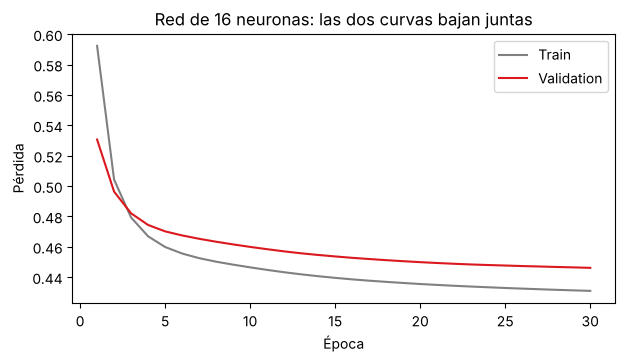

In [19]:
def graficar_curva(curva, titulo, ax=None):
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    ax.plot(curva['loss'], color='gray', label='Train')
    ax.plot(curva['val_loss'], color='#DA181E', label='Validation')
    ax.set_xlabel('Época'); ax.set_ylabel('Pérdida'); ax.set_title(titulo); ax.legend()
    return ax

graficar_curva(curva_simple, 'Red de 16 neuronas: las dos curvas bajan juntas')
plt.show()

**Cómo leerla:** las dos curvas bajan rápido en las primeras épocas y después más despacio. La de Validation queda un poco por encima de la de Train y sigue bajando: **la red todavía está aprendiendo cosas que generalizan**. Es una curva sana.

## 4.5 Sobreajuste: una red demasiado grande

¿Y si usamos una red mucho mayor (dos capas de 256 neuronas, más de 70 000 parámetros) y la entrenamos 60 épocas?

Parámetros: 72193


60 épocas en 31 s · pérdida Train = 0.267 · pérdida Validation = 0.615 · AUC Validation = 0.703


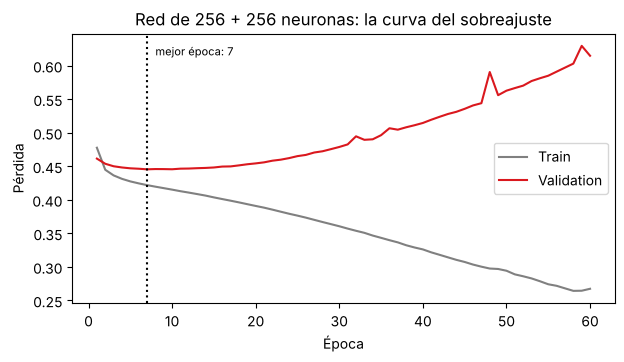

In [20]:
red_grande = crear_red(capas=(256, 256))
print('Parámetros:', red_grande.count_params())
curva_grande = entrenar(red_grande, X_train_n, X_val_n, epocas=60)

ax = graficar_curva(curva_grande, 'Red de 256 + 256 neuronas: la curva del sobreajuste')
mejor_epoca = curva_grande['val_loss'].idxmin()
ax.axvline(mejor_epoca, color='black', linestyle=':'); ax.text(mejor_epoca + 1, ax.get_ylim()[1] * 0.95, f'mejor época: {mejor_epoca}', fontsize=8)
plt.show()

**Lectura: la figura más importante de la unidad.**

- La pérdida en **Train baja sin parar**: con 72 000 parámetros y 18 000 clientes, la red puede memorizarlos.
- La pérdida en **Validation baja durante pocas épocas y después sube**, cada vez más. A partir de ahí, lo que la red aprende es memoria de Train que no sirve para clientes nuevos.
- Al final, su AUC en Validation es **peor que el de la red de 16 neuronas**.

Es el árbol sin límite de profundidad y el KNN con k = 1 de la Unidad 1, en versión red neuronal: **más capacidad no es mejor**.

## 4.6 Tres frenos contra el sobreajuste

| Freno | Qué hace | En Keras |
|---|---|---|
| **Red más pequeña** | menos parámetros, menos memoria | `capas=(32, 16)` |
| **Dropout** | en cada paso apaga al azar una fracción de las neuronas; la red no puede depender de ninguna en particular (se parece al sorteo de columnas del Random Forest) | `layers.Dropout(0.3)` |
| **Parada temprana** | vigila la pérdida de Validation y **detiene** el entrenamiento cuando deja de mejorar; se queda con los pesos de la mejor época | `EarlyStopping` |

70 épocas en 31 s · pérdida Train = 0.431 · pérdida Validation = 0.436 · AUC Validation = 0.777


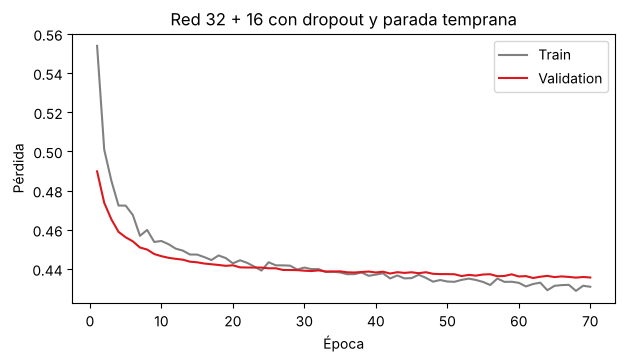

In [21]:
parada = keras.callbacks.EarlyStopping(
    monitor='val_loss',            # vigila la pérdida en Validation
    patience=8,                    # si no mejora en 8 épocas seguidas, se detiene
    restore_best_weights=True)     # y recupera los pesos de la mejor época

red_final = crear_red(capas=(32, 16), dropout=0.3)
curva_final = entrenar(red_final, X_train_n, X_val_n, epocas=100, parada=parada)

graficar_curva(curva_final, 'Red 32 + 16 con dropout y parada temprana')
plt.show()

**Lectura:** pedimos hasta 100 épocas y la parada temprana detuvo el entrenamiento antes, cuando la pérdida de Validation llevaba 8 épocas sin mejorar. Las dos curvas quedan pegadas: no hay memoria de más.

Un detalle: con dropout, la pérdida de **Train puede quedar por encima de la de Validation**. No es un error: durante el entrenamiento la red trabaja con neuronas apagadas, y al validar las usa todas.

## 4.7 La tasa de aprendizaje y el tamaño del lote

Repetimos con Keras el experimento de la parte 3.3: la red de 16 neuronas, 15 épocas, cuatro tasas de aprendizaje.

In [22]:
filas = []
for tasa in [0.00001, 0.001, 0.1, 1.0]:
    print(f'tasa = {tasa}: ', end='')
    curva = entrenar(crear_red(capas=(16,), tasa=tasa), X_train_n, X_val_n, epocas=15)
    filas.append({'Tasa de aprendizaje': tasa, 'Pérdida Validation': curva['val_loss'].iloc[-1], 'AUC Validation': curva['val_auc'].iloc[-1]})
pd.DataFrame(filas).set_index('Tasa de aprendizaje').round(3)

tasa = 1e-05: 

15 épocas en 6 s · pérdida Train = 0.666 · pérdida Validation = 0.663 · AUC Validation = 0.600
tasa = 0.001: 

15 épocas en 6 s · pérdida Train = 0.440 · pérdida Validation = 0.454 · AUC Validation = 0.752
tasa = 0.1: 

15 épocas en 7 s · pérdida Train = 0.453 · pérdida Validation = 0.456 · AUC Validation = 0.743
tasa = 1.0: 

15 épocas en 6 s · pérdida Train = 0.534 · pérdida Validation = 0.529 · AUC Validation = 0.500


,Pérdida Validation,AUC Validation
Tasa de aprendizaje,,
0.00001,0.663,0.600
0.00100,0.454,0.752
0.10000,0.456,0.743
1.00000,0.529,0.500


**Lectura:**

- **0.00001**: paso tan corto que en 15 épocas casi no se movió (la pérdida sigue cerca de 0.66).
- **0.001**: el valor por defecto de Adam. Funciona.
- **0.1**: llega a un resultado parecido, de forma más inestable.
- **1.0**: paso tan largo que la red se rompe: termina respondiendo casi lo mismo para todos los clientes y el AUC cae a 0.5.

Y el tamaño del lote, con 10 épocas:

In [23]:
filas = []
for lote in [32, 256, 4096]:
    print(f'lote = {lote}: ', end='')
    inicio = time.time()
    curva = entrenar(crear_red(capas=(16,)), X_train_n, X_val_n, epocas=10, lote=lote)
    filas.append({'Tamaño del lote': lote, 'Pasos por época': int(np.ceil(len(X_train_n) / lote)),
                  'Segundos': time.time() - inicio, 'AUC Validation': curva['val_auc'].iloc[-1]})
pd.DataFrame(filas).set_index('Tamaño del lote').round(3)

lote = 32: 

10 épocas en 11 s · pérdida Train = 0.435 · pérdida Validation = 0.449 · AUC Validation = 0.760
lote = 256: 

10 épocas en 3 s · pérdida Train = 0.455 · pérdida Validation = 0.468 · AUC Validation = 0.721
lote = 4096: 

10 épocas en 2 s · pérdida Train = 0.590 · pérdida Validation = 0.586 · AUC Validation = 0.617


,Pasos por época,Segundos,AUC Validation
Tamaño del lote,,,
32,563,11.530,0.760
256,71,3.004,0.721
4096,5,1.881,0.617


**Lectura:** con lotes de 32 se dan 563 pasos por época: la red aprende más en 10 épocas, pero tarda más. Con lotes de 4 096 solo hay 5 pasos por época: es rapidísimo, pero en 10 épocas dio 50 pasos en total y apenas aprendió.

**Lote pequeño = muchos pasos ruidosos; lote grande = pocos pasos precisos.** Valores entre 32 y 256 suelen funcionar bien. Si se agranda el lote, hay que entrenar más épocas.

# 5. La red final frente a las líneas base (3.5)

**La pregunta de siempre:** ¿la red neuronal le gana a lo que ya teníamos? Comparamos en la misma Validation:

- la **regla del atraso** (Unidad 1);
- la **regresión logística**, que es una red de una sola neurona;
- **Random Forest** y **boosting**, los mejores de la Unidad 1;
- la **red 32 + 16** con dropout y parada temprana.

Medimos el AUC (¿ordena bien?) y el Brier (¿probabilidades creíbles?, Unidad 2).

In [24]:
resultados = {}

def registrar(nombre, prob, parametros='—'):
    resultados[nombre] = {'AUC': round(roc_auc_score(y_val, prob), 3), 'Brier': round(brier_score_loss(y_val, prob), 3), 'Parámetros': str(parametros)}

# La regla del atraso no da probabilidades: solo medimos cómo ordena (AUC), con los meses de atraso como puntaje
resultados['Regla del atraso'] = {'AUC': round(roc_auc_score(y_val, X_val['atraso_sep']), 3), 'Brier': np.nan, 'Parámetros': '—'}

logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
registrar('Regresión logística (1 neurona)', logistica.predict_proba(X_val)[:, 1], 24)

bosque = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_train, y_train)
registrar('Random Forest', bosque.predict_proba(X_val)[:, 1])

boosting = GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42).fit(X_train, y_train)
registrar('Boosting', boosting.predict_proba(X_val)[:, 1])

registrar('Red 16 neuronas', red_simple.predict(X_val_n, verbose=0).ravel(), red_simple.count_params())
registrar('Red 256 + 256 (sobreajustada)', red_grande.predict(X_val_n, verbose=0).ravel(), red_grande.count_params())
registrar('Red 32 + 16 con dropout', red_final.predict(X_val_n, verbose=0).ravel(), red_final.count_params())

comparacion = pd.DataFrame(resultados).T.sort_values('AUC', ascending=False)
comparacion

,AUC,Brier,Parámetros
Random Forest,0.783,0.135,—
Boosting,0.781,0.135,—
Red 32 + 16 con dropout,0.777,0.137,1313
Red 16 neuronas,0.765,0.138,401
Regresión logística (1 neurona),0.724,0.145,24
Red 256 + 256 (sobreajustada),0.703,0.173,72193
Regla del atraso,0.683,NaN,—


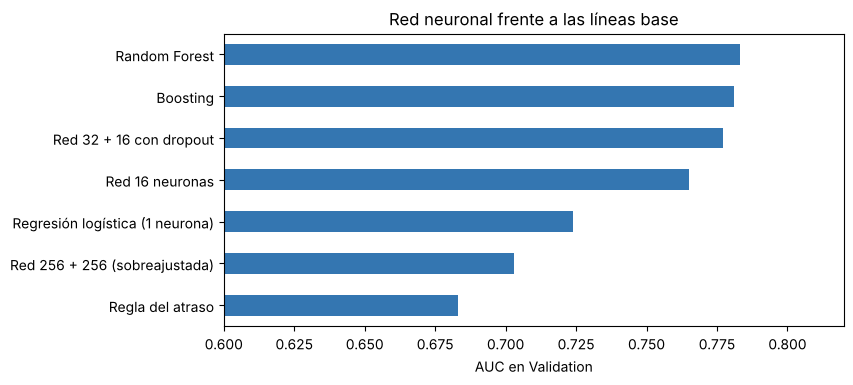

In [25]:
ax = comparacion['AUC'].astype(float).sort_values().plot(kind='barh', figsize=(8, 3.8), color='#3476B1')
ax.set_xlim(0.6, 0.82); ax.set_xlabel('AUC en Validation'); ax.set_title('Red neuronal frente a las líneas base')
plt.show()

### Lectura

| Modelo | AUC Validation | Comentario |
|---|---:|---|
| Random Forest | ≈ 0.78 | sigue primero |
| Boosting | ≈ 0.78 | empatado |
| **Red 32 + 16 con dropout** | ≈ 0.78 | **alcanza a los árboles; no los supera** |
| Red de 16 neuronas | ≈ 0.76 | cerca, con 401 parámetros |
| Regresión logística | ≈ 0.72 | una neurona: solo una línea recta |
| Red 256 + 256 | ≈ 0.70 | la más grande es la peor de las redes |
| Regla del atraso | 0.68 | la línea base |

Cuatro ideas:

1. **De una neurona a una capa oculta hay un salto real** (de 0.72 a 0.76): las capas permiten aprender combinaciones, como la del atraso con el cupo.
2. **La red empata con los conjuntos de árboles, no les gana.** En datos tabulares de este tamaño es lo habitual: Random Forest y boosting son muy difíciles de superar y exigen mucho menos ajuste.
3. **Más grande no es mejor**: la red de 72 000 parámetros quedó por debajo de la de 401.
4. La misma conclusión del Módulo 5: **lo complejo tiene que demostrar que le gana a lo simple**, en datos que no vio.

**¿Dónde sí ganan las redes neuronales?** Cuando hay muchísimos datos y la entrada no es una tabla: imágenes, texto, audio, series muy largas. Ahí las capas aprenden solas las variables que en una tabla construimos a mano. En el Módulo 6 las estudiamos con una tabla porque así se entiende el mecanismo.

## Guardar la red para la Unidad 4

En la Unidad 4 abriremos el Test con todos los modelos del módulo. Para no reentrenar, guardamos la red final.

In [26]:
from pathlib import Path

carpeta = Path('resultados_modulo6')
carpeta.mkdir(exist_ok=True)
red_final.save(carpeta / 'red_impago.keras')
print('Red guardada en', carpeta / 'red_impago.keras')

Red guardada en resultados_modulo6/red_impago.keras


# Actividad 3: interpretar y comparar una MLP (20 puntos)

Se entrega este notebook con la sección siguiente completada. La práctica empieza el 19-11 y se termina el 23-11 (1 hora).

**Qué hay que hacer:**

1. Elegir **una** arquitectura distinta de las de la clase (por ejemplo, otra cantidad de neuronas o de capas, otro dropout, otra tasa de aprendizaje u otro tamaño de lote).
2. Entrenarla con `crear_red` y `entrenar`, y dibujar su curva de aprendizaje.
3. Responder, en una celda de texto:
   - ¿La curva muestra sobreajuste? ¿En qué época se ve?
   - ¿Le gana tu red a la regla del atraso, a la regresión logística y al Random Forest en Validation?
   - Si el banco te pidiera recomendar un modelo, ¿cuál elegirías y por qué? Considera el AUC, el Brier, la facilidad para explicarlo y el costo de mantenerlo.

**No se evalúa quién consigue el AUC más alto**, sino la lectura de la curva y la justificación.

30 épocas en 14 s · pérdida Train = 0.433 · pérdida Validation = 0.446 · AUC Validation = 0.764


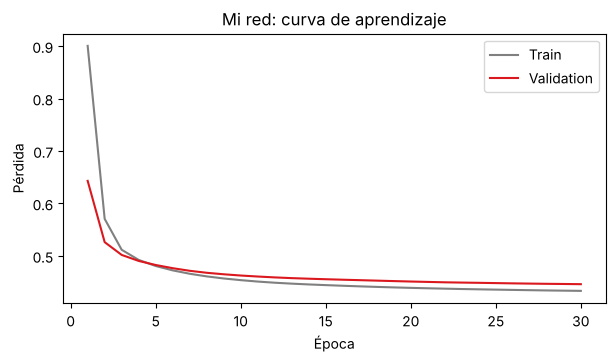

,AUC,Brier,Parámetros
Random Forest,0.783,0.135,—
Boosting,0.781,0.135,—
Red 32 + 16 con dropout,0.777,0.137,1313
Red 16 neuronas,0.765,0.138,401
Mi red,0.765,0.138,201
Regresión logística (1 neurona),0.724,0.145,24
Red 256 + 256 (sobreajustada),0.703,0.173,72193
Regla del atraso,0.683,NaN,—


In [27]:
# --- Tu red ---------------------------------------------------------------
# Cambia los valores de esta celda. Ejemplos: capas=(64,), capas=(64, 32, 16), dropout=0.5, tasa=0.01, lote=64
mi_red = crear_red(capas=(8,), dropout=0.0, tasa=0.001)
mi_curva = entrenar(mi_red, X_train_n, X_val_n, epocas=30, lote=128)

graficar_curva(mi_curva, 'Mi red: curva de aprendizaje')
plt.show()

registrar('Mi red', mi_red.predict(X_val_n, verbose=0).ravel(), mi_red.count_params())
pd.DataFrame(resultados).T.sort_values('AUC', ascending=False)

**Tus respuestas (edita esta celda):**

1. ¿La curva muestra sobreajuste? ...
2. ¿Le gana a las líneas base? ...
3. ¿Qué modelo recomendarías al banco y por qué? ...

## Checklist de la unidad

- [ ] ¿Puedo calcular a mano la salida de una neurona (suma ponderada y activación)?
- [ ] ¿Puedo propagar un dato por una red pequeña, capa por capa?
- [ ] ¿Puedo explicar la pérdida como "castigo por equivocarse con seguridad"?
- [ ] ¿Puedo explicar el descenso del gradiente con la montaña y la niebla?
- [ ] ¿Sé qué reparte la retropropagación?
- [ ] ¿Normalicé las entradas con la media y la desviación de Train?
- [ ] ¿Miré la curva de aprendizaje antes de mirar el AUC?
- [ ] ¿Comparé la red con la línea base en la misma Validation?
- [ ] ¿Dejé el Test sin tocar?